# 09 | Comparisons with published EEG findings

Test selected published patterns using the continuous borderline score. The cell documents the frequency bands and denominator used for relative power.

**Run in Colab.** See the repository README for Drive access and input paths. Run cells in order and start with notebook 01. Generated files belong in the private working directory. Saved outputs show the original study run.


In [1]:
from pathlib import Path
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, iqr
from IPython.display import display

if 'EEG_WORK' not in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
project = Path('/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab')
work = Path(os.environ.get('EEG_WORK', project/'ورودی‌های خصوصی بازتحلیل'/'derived'))
cache = Path(os.environ.get('EEG_REFERENCE_DIR', work/'inputs'))
raw_dir = Path(os.environ.get('EEG_RAW', '/content/eeg_mcmi_raw'))
for path in [work,cache,raw_dir]:
    path.mkdir(parents=True,exist_ok=True)
os.chdir(work)
def drive_service():
    from google.colab import auth
    from googleapiclient.discovery import build
    auth.authenticate_user()
    return build('drive','v3',cache_discovery=False)
def read_existing_drive_file(service,file_id,destination):
    from googleapiclient.http import MediaIoBaseDownload
    temp=destination.with_suffix(destination.suffix+'.part')
    with temp.open('wb') as out:
        reader=MediaIoBaseDownload(out,service.files().get_media(fileId=file_id))
        done=False
        while not done:
            _,done=reader.next_chunk()
    temp.replace(destination)
if not (cache/'scores.xlsx').exists():
    original=Path('/content/drive/MyDrive/MCMI_results.xlsx')
    if original.exists():
        shutil.copyfile(original,cache/'scores.xlsx')
    else:
        read_existing_drive_file(drive_service(),'1EOvKbEfvLAQPTjizNE9DEUR9Ik8xBsiy',cache/'scores.xlsx')
scores = pd.read_excel(cache/'scores.xlsx',index_col=0)
assert scores.index.is_unique
manifest=work/'joint/manifest.json'
ids=sorted(s for s in [Path(v[0]).stem for v in json.loads(manifest.read_text())] if scores.loc[s,'سن']>=18) if manifest.exists() else []
channels='Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T3 T4 T5 T6 Fz Cz Pz'.split()
def figure(name):
    plt.tight_layout()
    plt.savefig(work/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()

Mounted at /content/drive


## Delta, alpha, gamma, and coherence

Use the electrodes reported by Rezaei et al. and the parietal electrodes considered by Deiber et al. Average epoch-level Welch spectra. Divide each channel’s band power by its power from 2 to below 40 Hz. Compute coherence using mean cross- and auto-spectra.

[Rezaei et al.](https://doi.org/10.32598/CJNS.10.39.177.3) · [Deiber et al.](https://doi.org/10.1007/s10548-023-01005-3)


,0
delta,0.273047
alpha,-0.471466
gamma_C4,0.052678
coherence_alpha,-0.042142
parietal_delta,0.359965
parietal_alpha,-0.363477


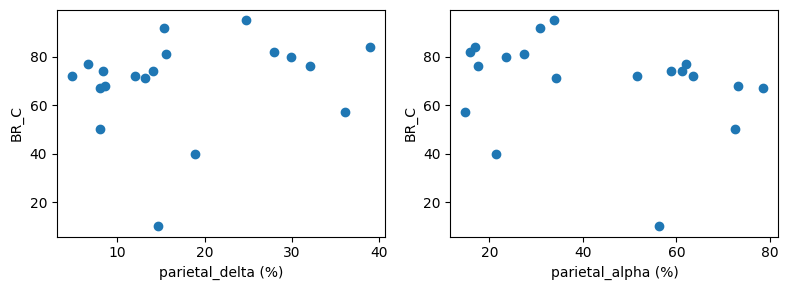

In [2]:
assert len(ids)==19, 'Run notebook 01 first.'
from scipy.signal import welch,csd
from scipy.stats import spearmanr
groups={'delta':['Fp1','Fp2','F7','F8','C3','P3','T5','O1'],
        'alpha':['F7','F4','Fz','C4','Cz','P4','T4'],
        'gamma':['C4'],'parietal':['P3','Pz','P4']}
couples=[('Fp1','Fp2'),('F7','F8'),('Fz','Cz'),('T3','T4')]
rows=[]
for sid in ids:
    with np.load(work/'out'/(sid+'.npz')) as z:
        x=z['eeg'].astype(float); names=[c.split('-')[0] for c in z['channels']]
    f,ps=welch(x,500,nperseg=500,noverlap=250)
    ps=ps.mean(0)
    total=ps[:,(f>=2)&(f<40)].sum(1)
    def relative(chs,lo,hi):
        ix=[names.index(c) for c in chs]
        return np.mean(ps[ix][:,(f>=lo)&(f<hi)].sum(1)/total[ix])
    coh=[]
    for c,d in couples:
        i,j=names.index(c),names.index(d)
        _,xy=csd(x[:,i],x[:,j],500,nperseg=500,noverlap=250)
        ratio=np.abs(xy.mean(0))**2/(ps[i]*ps[j])
        coh.append(np.mean(ratio[(f>=8)&(f<13)]))
    rows.append([sid,relative(groups['delta'],2,4),relative(groups['alpha'],8,13),
                 relative(groups['gamma'],30,40),np.mean(coh),relative(groups['parietal'],2,4),relative(groups['parietal'],8,13)])
table=pd.DataFrame(rows,columns=['subject','delta','alpha','gamma_C4','coherence_alpha','parietal_delta','parietal_alpha']).set_index('subject')
result=table.apply(lambda x:spearmanr(x,scores.loc[x.index,'BR_C']).statistic)
result.to_csv('literature_ROIs.csv')
display(result)
fig,axes=plt.subplots(1,2,figsize=(8,3))
for ax,col in zip(axes,['parietal_delta','parietal_alpha']):
    ax.scatter(100*table[col],scores.loc[table.index,'BR_C']);ax.set(xlabel=col+' (%)',ylabel='BR_C')
figure('09_literature')

## Predicting 4B

Nosouhi and Esghaei report the correlation between predicted and observed scores. RMSE and Q² capture different aspects of prediction. Notebook 07 calculates out-of-fold predictions.

[Nosouhi and Esghaei](https://doi.org/10.1109/IICAI70155.2026.11621004)


In [3]:
path = work / 'prediction.csv'
if not path.exists():
    runs = sorted((work / 'brant_runs').glob('fresh_*/prediction.csv'), key=lambda p: p.stat().st_mtime)
    if runs:
        path = runs[-1]
if path.exists():
    pred=pd.read_csv(path)
    display(pred.query("score=='BR_4B' and model in ['train_only_RF','train_only_ridge']"))
else:
    print('Run notebook 07 to generate the prediction table.')

برای جدول پیش‌بینی، نوت‌بوک ۷ را اجرا کنید.
